# **Problem Set 2**
## CHEM 5541 - Chemical Dynamics
### *Samuel Arnold*
### *9/11/26*
***

## 1.) 

### 1a.) 

| Temperature [$^{\circ}$ C] | 0 | 20 | 40 | 60 |
|:--- | :---: | :---: | :---: | ---: |
| $k_r$ / $10^{-5} \text{s}^{-1}$ | 2.46 | 47.5 | 576 | 5480 |

With the Arrhenius equation:

$$k_r = Ae^{-E_a/RT}$$

we can then linearize by taking the natural logarithim to find:

$$\ln{k_r} = \ln{A} - \left(\frac{E_a}{RT}\right)$$

This can then be rearranged to the $y = mx + b$ form with respect to inverse temperature ($T^{-1}$):

$$\ln{k_r} = - \frac{E_a}{R} \left(\frac{1}{T}\right) + \ln{A}$$

We can then fit this to the data by taking $\ln(k_r)$ and $1/T$:

| Temperature [$^{\circ}$ C] | 0 | 20 | 40 | 60 |
|:--- | :---: | :---: | :---: | ---: |
| $k_r$ [$\text{s}^{-1}$] | 2.46 $\times 10^{-5}$| 47.5 $\times 10^{-5}$| 576 $\times 10^{-5}$| 5480 $\times 10^{-5}$|
| Temperature [$K$] | 273.15 | 293.15 | 313.15 | 333.15 |
| $1/T$ [$K^{-1}$] | 0.0037 | 0.0034 | 0.0032 | 0.0030 |
| $\ln(k_r)$ | -10.613 | -7.652 | -5.157 | -2.904 |

Fit Determined Activation Energy (E_a): 92164.1865 J/mol
Pre-exponential factor (A): 1.4105e13 s^-1


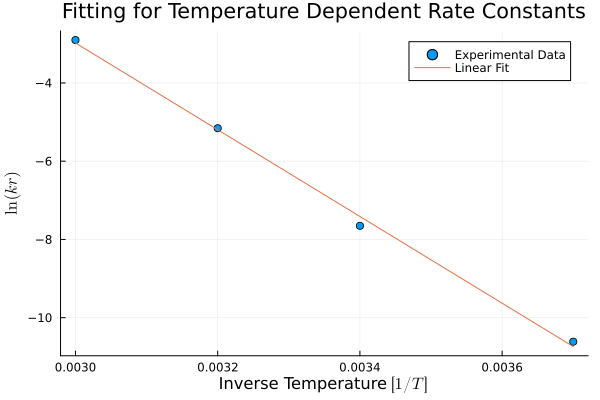

In [33]:
using Plots

gr() 

R = 8.314 # J / mol k

inverse_T = [0.0037, 0.0034, 0.0032, 0.0030]
ln_kr = [-10.613, -7.652, -5.157, -2.904]

length_inverse_T = length(inverse_T)
avg_inverse_T = sum(inverse_T) / length_inverse_T
avg_ln_kr = sum(ln_kr) / length_inverse_T

numerator = sum((inverse_T .- avg_inverse_T) .* (ln_kr .- avg_ln_kr))
denominator = sum((inverse_T .- avg_inverse_T) .^ 2)

slope = numerator / denominator
intercept = avg_ln_kr - (slope * avg_inverse_T)

E_a = - slope * R
A = exp(intercept)

println("Fit Determined Activation Energy (E_a): ", round(E_a, digits=4), " J/mol")
println("Pre-exponential factor (A): ", round(A, digits=-9), " s^-1")

inverse_T_range = range(minimum(inverse_T), maximum(inverse_T), length=100)
fit_line = slope .* inverse_T_range .+ intercept

scatter(
    inverse_T, 
    ln_kr,
    title="Fitting for Temperature Dependent Rate Constants", 
    label="Experimental Data",
    xlabel=raw"Inverse Temperature $[1/T]$", 
    ylabel=raw"$\ln(kr)$"
)

plot!(
    inverse_T_range,
    fit_line,
    label="Linear Fit"
)

### 1b.)

The half-life can be found by using:

$$t_{1/2} = \frac{\ln(2)}{k_r}$$

with the value of $k_r$ at 80 $^{\circ}$C being found by applying the fit equation:

$$\ln(k_{80^{\circ} \text{C}}) = - \frac{92,164.1865 \text{ [J/mol]}}{R} (\frac{1}{353.15 \text{ K}}) + \ln(1.4105 \times 10^{13} \text{ [s$^{-1}$]})$$



In [39]:
k_80 = exp(-(E_a / R) * (1/353.15) + log(A))
println("Fit Determined Rate at 80 C (k_80): ", round(k_80, digits=4), " s^-1")

half_life = log(2.00) / k_80
println("Fit Determined Half-life (t_1/2): ", round(half_life, digits=4), " s")

Fit Determined Rate at 80 C (k_80): 0.3287 s^-1
Fit Determined Half-life (t_1/2): 2.1087 s


So that:

$$k_{80^{\circ} \text{C}} = 0.3287 \text{ s}^{-1}$$

such that the half-life is:

$$t_{1/2} = 2.1087 \text{ s}$$

***

## 2.) 

### 2a.) 

$$\text{CH}_3 + \text{CH}_3 \xrightarrow{k_r} products$$

$$\frac{d[\text{CH}_3]}{dt} = - 2k_r[\text{CH}_3]^2$$

$$\frac{d[\text{CH}_3]}{[\text{CH}_3]^2} = - 2k_r dt$$

$$\int_{[\text{CH}_3]_0}^{[\text{CH}_3]_t} \frac{d[\text{CH}_3]}{[\text{CH}_3]^2} = -2k_r \int_{0}^{t} dt$$

$$- \frac{1}{[\text{CH}_3]} \bigg|_{[\text{CH}_3]_0}^{[\text{CH}_3]_t} = -2k_r t$$

$$\frac{1}{[\text{CH}_3]_t} - \frac{1}{[\text{CH}_3]_0} = 2k_r t$$

$$\frac{[\text{CH}_3]_0}{[\text{CH}_3]_t} - 1 = 2k_r [\text{CH}_3]_0 t$$

$$\frac{[\text{CH}_3]_0}{[\text{CH}_3]_t} = 1 +  2k_r [\text{CH}_3]_0 t$$

Since the intensity $I(t)$ is proportional to $[\text{CH}_3]$, if we plot the ratio of the intensities 1:1 with the concentrations, we can see if we observe the linear behavior predicted by the rate equation.

Slope: 5691.1327


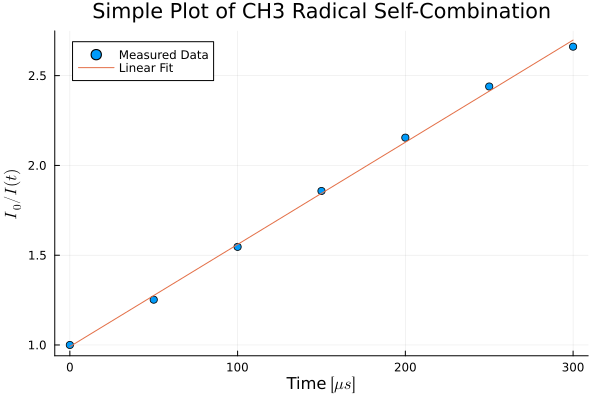

In [88]:
using Plots

gr() 

time = [0e-6, 50e-6, 100e-6, 150e-6, 200e-6, 250e-6, 300e-6]
intensity = [8.49, 6.78, 5.49, 4.57, 3.94, 3.48, 3.19]

intensity_ratio = intensity[1] ./ intensity

length_time = length(time)
avg_time = sum(time) / length_time
avg_intensity_ratio = sum(intensity_ratio) / length_time

numerator = sum((time.- avg_time) .* (intensity_ratio .- avg_intensity_ratio))
denominator = sum((time .- avg_time) .^ 2)

slope = numerator / denominator
intercept = avg_intensity_ratio - (slope * avg_time)

println("Slope: ", round(slope, digits=4))

time_range = range(minimum(time), maximum(time), length=100)
fit_line = slope .* time_range .+ intercept

scatter(
    time*10e5, 
    intensity_ratio,
    title="Simple Plot of CH3 Radical Self-Combination", 
    label="Measured Data",
    xlabel=raw"Time $[\mu s]$", 
    ylabel=raw"$I_0 / I(t)$"
)

plot!(
    time_range*10e5,
    fit_line,
    label="Linear Fit"
)

As seen in the plot, we observe a linear behavior with the second-order integrated rate law, so that the reaction fits well with the kinetic model.

### 2b.)

No, while $I(0)$ is proportional to $[\text{CH}_3]_0$ there must be some kind of scaling factor to be able to convert the arbitrary units to the actual concentration such that the slope can provide calculatable data when $k_r$ is multiplied by $[\text{CH}_3]_0$.

### 2c.)

With the concentration linked to the time at $t=0$, $k_r$ can be found, but also the half-life since:

$$t_{1/2} = \frac{1}{2k_r [\text{CH}_3]_0}$$

So finding $k_r$ with the slope:

$$m = 2 k_r [\text{CH}_3]_0$$

$$k_r = \frac{m} {2[\text{CH}_3]_0}$$

In [82]:
k_r = slope / (2 * 1.0e14)
println("Fit Determined Rate: ", k_r, " s^-1")

half_life = 1 / (2 * k_r * 1.0e14)
half_life_us = half_life * 1e6
println("Fit Determined Half-life (t_1/2): ", round(half_life_us, digits=4), " microseconds")

Fit Determined Rate: 2.8455663687389252e-11 s^-1
Fit Determined Half-life (t_1/2): 175.7119 microseconds


$$k_r = 2.8456 \times 10^{-11} \text{ [cm}^3 \text{s}^{-1}]$$

$$t_{1/2} = 175.7119 \text{ [}\mu s]$$

***

## 3.) 

### 3a.)

$$k_r = A e^{-E_a / RT}$$

$$\ln(k_r) = \ln(A) - \frac{E_a}{RT}$$

$$\frac{d (\ln(k_r))}{dt} = \frac{E_a}{RT^2}$$

$$E_a = RT^2\frac{d (\ln(k_r))}{dt}$$

$$E_a = E_a = \text{constant}$$

### 3b.)

$$k_r = A' \cdot T^m \cdot e^{-E_0 / RT}$$

$$\ln(k_r) = \ln(A') + m \ln(T) - \frac{E_0}{RT}$$

$$\frac{d (\ln(k_r))}{dt} = \frac{m}{T} + \frac{E_0}{RT^2}$$

using $E_a / RT^2$ from 3a. and setting the derivatives equal

$$E_a = RT^2(\frac{m}{T} + \frac{E_0}{RT^2})$$

$$E_a = mRT + E_0$$

### 3c.)

In the "regular" Arrhenius equation, the activation energy is constant as seen in 3a. In the modified equation, however, the resulting $E_a$ is temperature dependent, as seen in 3b.

***

## 4.)

## 4a.) 

Since substance S decomposes into both B and C, the rate laws for B and C both are dependent on the concentration of S:

$$\text{Rate}_B = k_B[S] \hspace{0.5cm} \text{and} \hspace{0.5cm} \text{Rate}_C = k_C[S]$$

If the rates are the same for this temperature:

$$k_B[S] = k_C[S]$$

Then:

$$k_B = k_C$$

Such that:

$$A_B e^{-E_{a,B}/RT} = A_C e^{-E_{a,C}/RT}$$

$$\frac{A_B}{A_C} = \frac{e^{-E_{a,C}/RT}}{e^{-E_{a,B}/RT}}$$

$$\frac{A_B}{A_C} = e^{E_{a,B}-E_{a,C}/RT}$$

$$\ln\left(\frac{A_B}{A_C}\right) = \frac{E_{a,B}-E_{a,C}}{RT}$$

$$T = \frac{E_{a,B}-E_{a,C}}{R\ln\left(\frac{A_B}{A_C}\right)}$$

In [92]:
E_ab = 126000
E_ac = 83700
A_b = 10e15
A_c = 10e13

T = (E_ab - E_ac) / (R * log(A_b/A_c))

println("Temperature at which the rates are the same: ", round(T, digits=4), " K")

Temperature at which the rates are the same: 1104.8025 K


### 4b.) 


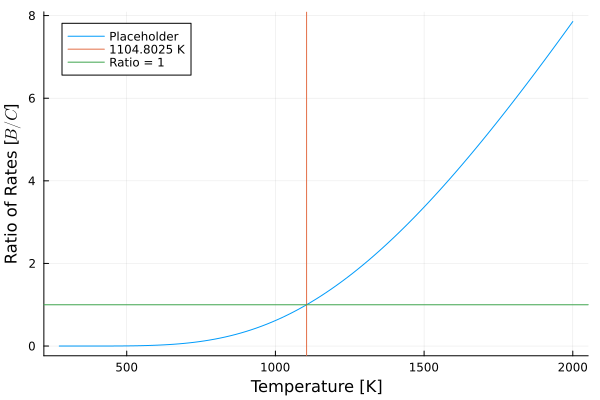

In [118]:
using Plots

gr()

T_range = range(273.15, 2000, length=100)

rate_ratio = (A_b/A_c) .* exp.(-(E_ab - E_ac) ./ (R .* T_range))

Plots.plot(
    T_range,
    rate_ratio,
    label="Placeholder",
    xlabel="Temperature [K]",
    ylabel=raw"Ratio of Rates [$B/C$]"
)

Plots.vline!(
    [1104.8025],
    label = "1104.8025 K"
)

Plots.hline!(
    [1],
    label = "Ratio = 1"
)

As the temperature increases, the rate of B increases more than the rate of C. Indicating that while the activation energy of B is higher, the 100 times higher frequency factor causes it to outpace C.

***

## 5.)

### a.) 

The rate laws for A and B can be described by:

$$\frac{d[A]}{dt} = -k_1[A] + k_2[B]$$
$$\frac{d[B]}{dt} = k_1[A] - k_2[B]$$

101×3 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L) 
     │ Float64  Float64     Float64    
─────┼─────────────────────────────────
   1 │     0.0    1.0         0.0
   2 │     1.0    0.9         0.1
   3 │     2.0    0.82        0.18
   4 │     3.0    0.756       0.244
   5 │     4.0    0.7048      0.2952
   6 │     5.0    0.66384     0.33616
   7 │     6.0    0.631072    0.368928
   8 │     7.0    0.604858    0.395142
   9 │     8.0    0.583886    0.416114
  10 │     9.0    0.567109    0.432891
  11 │    10.0    0.553687    0.446313
  12 │    11.0    0.54295     0.45705
  13 │    12.0    0.53436     0.46564
  14 │    13.0    0.527488    0.472512
  15 │    14.0    0.52199     0.47801
  16 │    15.0    0.517592    0.482408
  17 │    16.0    0.514074    0.485926
  18 │    17.0    0.511259    0.488741
  19 │    18.0    0.509007    0.490993
  20 │    19.0    0.507206    0.492794
  21 │    20.0    0.505765    0.494235
  22 │    21.0    0.504612    0.495388
  23 │    22.0    0.503689   

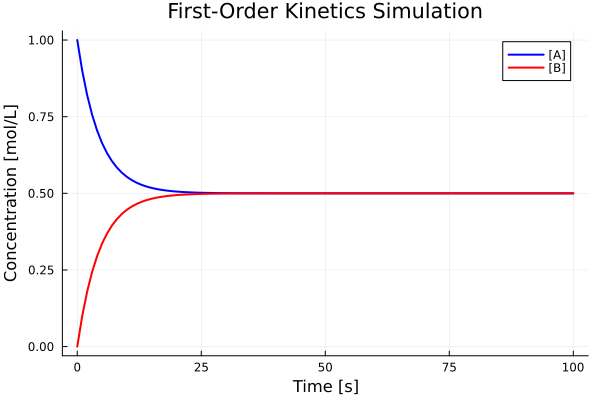

In [245]:
using CSV
using DataFrames
using Plots

function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    k_1 = 0.1         # s^-1
    k_2 = 0.1         # s^-1
    delta_t = 1.0     # s
    T = 100           # s


    t_array = []
    A_array = []
    B_array = []

    A = A_0
    B = B_0
    t = 0.0

    open("S.Arnold_PS2_Q5a_output.txt", "w") do io
        write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, k_1=$k_1 s^-1, k_2=$k_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
        write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\n")

        while t <= T
            push!(t_array, t)
            push!(A_array, A)
            push!(B_array, B)
            
            write(io, "$t\t$A\t$B\n")
            
            # Rate laws
            dA = (-k_1 * A + k_2 * B) * delta_t
            dB = (k_1 * A - k_2 * B) * delta_t
            
            A += dA
            B += dB
            t += delta_t
        end
    end

    df = CSV.read("S.Arnold_PS2_Q5a_output.txt", DataFrame, delim='\t', comment="#")
    print(df)

    Plots.plot(
        t_array, 
        A_array,
        title="First-Order Kinetics Simulation",
        label="[A]", 
        xlabel="Time [s]",
        ylabel="Concentration [mol/L]",
        color=:blue, 
        linewidth=2
    )

    plot!(
        t_array, 
        B_array, 
        label="[B]", 
        color=:red, 
        linewidth=2
    )
end

kinetics_simulation()


$$[A]_{t=100s} = 0.50 \text{ mol/L}$$
$$[B]_{t=100s} = 0.50 \text{ mol/L}$$

### b.)

Since the species are at equilibrium already, no changes in the concentration occurs.

101×3 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L) 
     │ Float64  Float64     Float64    
─────┼─────────────────────────────────
   1 │     0.0         1.0         1.0
   2 │     1.0         1.0         1.0
   3 │     2.0         1.0         1.0
   4 │     3.0         1.0         1.0
   5 │     4.0         1.0         1.0
   6 │     5.0         1.0         1.0
   7 │     6.0         1.0         1.0
   8 │     7.0         1.0         1.0
   9 │     8.0         1.0         1.0
  10 │     9.0         1.0         1.0
  11 │    10.0         1.0         1.0
  12 │    11.0         1.0         1.0
  13 │    12.0         1.0         1.0
  14 │    13.0         1.0         1.0
  15 │    14.0         1.0         1.0
  16 │    15.0         1.0         1.0
  17 │    16.0         1.0         1.0
  18 │    17.0         1.0         1.0
  19 │    18.0         1.0         1.0
  20 │    19.0         1.0         1.0
  21 │    20.0         1.0         1.0
  22 │    21.0         1.0         1.0
  23 │

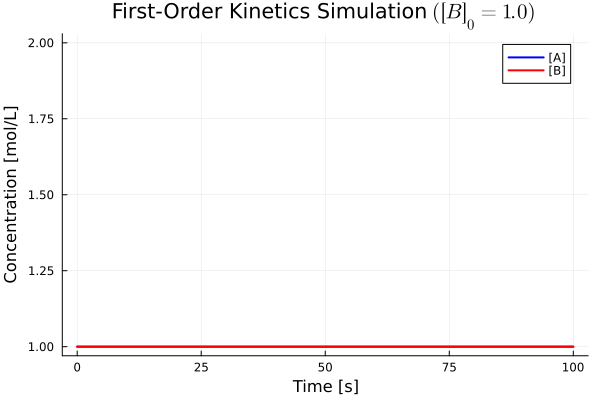

In [246]:
function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 1.0        # mol/L
    k_1 = 0.1         # s^-1
    k_2 = 0.1         # s^-1
    delta_t = 1.0     # s
    T = 100           # s


    t_array = []
    A_array = []
    B_array = []

    A = A_0
    B = B_0
    t = 0.0

    open("S.Arnold_PS2_Q5b_output.txt", "w") do io
        write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, k_1=$k_1 s^-1, k_2=$k_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
        write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\n")

        while t <= T
            push!(t_array, t)
            push!(A_array, A)
            push!(B_array, B)
            
            write(io, "$t\t$A\t$B\n")
            
            # Rate laws
            dA = (-k_1 * A + k_2 * B) * delta_t
            dB = (k_1 * A - k_2 * B) * delta_t
            
            A += dA
            B += dB
            t += delta_t
        end
    end

    df = CSV.read("S.Arnold_PS2_Q5b_output.txt", DataFrame, delim='\t', comment="#")
    print(df)

    Plots.plot(
        t_array, 
        A_array,
        title=raw"First-Order Kinetics Simulation $([B]_0 = 1.0)$",
        label="[A]", 
        xlabel="Time [s]",
        ylabel="Concentration [mol/L]",
        color=:blue, 
        linewidth=2
    )

    plot!(
        t_array, 
        B_array, 
        label="[B]", 
        color=:red, 
        linewidth=2
    )
end

kinetics_simulation()


### c.) 

101×3 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L) 
     │ Float64  Float64     Float64    
─────┼─────────────────────────────────
   1 │     0.0    1.0         0.5
   2 │     1.0    0.95        0.55
   3 │     2.0    0.91        0.59
   4 │     3.0    0.878       0.622
   5 │     4.0    0.8524      0.6476
   6 │     5.0    0.83192     0.66808
   7 │     6.0    0.815536    0.684464
   8 │     7.0    0.802429    0.697571
   9 │     8.0    0.791943    0.708057
  10 │     9.0    0.783554    0.716446
  11 │    10.0    0.776844    0.723156
  12 │    11.0    0.771475    0.728525
  13 │    12.0    0.76718     0.73282
  14 │    13.0    0.763744    0.736256
  15 │    14.0    0.760995    0.739005
  16 │    15.0    0.758796    0.741204
  17 │    16.0    0.757037    0.742963
  18 │    17.0    0.755629    0.744371
  19 │    18.0    0.754504    0.745496
  20 │    19.0    0.753603    0.746397
  21 │    20.0    0.752882    0.747118
  22 │    21.0    0.752306    0.747694
  23 │    22.0    0.751845

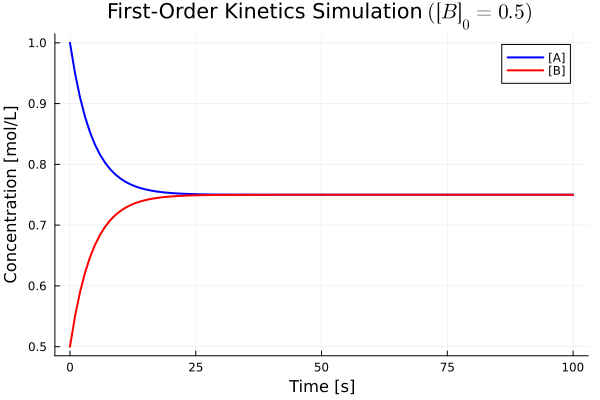

In [247]:
function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.5       # mol/L
    k_1 = 0.1         # s^-1
    k_2 = 0.1         # s^-1
    delta_t = 1.0     # s
    T = 100           # s


    t_array = []
    A_array = []
    B_array = []

    A = A_0
    B = B_0
    t = 0.0

    open("S.Arnold_PS2_Q5c_output.txt", "w") do io
        write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, k_1=$k_1 s^-1, k_2=$k_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
        write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\n")

        while t <= T
            push!(t_array, t)
            push!(A_array, A)
            push!(B_array, B)
            
            write(io, "$t\t$A\t$B\n")
            
            # Rate laws
            dA = (-k_1 * A + k_2 * B) * delta_t
            dB = (k_1 * A - k_2 * B) * delta_t
            
            A += dA
            B += dB
            t += delta_t
        end
    end

    df = CSV.read("S.Arnold_PS2_Q5c_output.txt", DataFrame, delim='\t', comment="#")
    print(df)

    Plots.plot(
        t_array, 
        A_array,
        title=raw"First-Order Kinetics Simulation $([B]_0 = 0.5)$",
        label="[A]", 
        xlabel="Time [s]",
        ylabel="Concentration [mol/L]",
        color=:blue, 
        linewidth=2
    )

    plot!(
        t_array, 
        B_array, 
        label="[B]", 
        color=:red, 
        linewidth=2
    )
end

kinetics_simulation()


$$[A]_{t\rightarrow\infty} = 0.75 \text{ mol/L}$$
$$[B]_{t\rightarrow\infty} = 0.75 \text{ mol/L}$$

### d.) 

Meaningful results stop when $k=0.6$ as it causes the concentration to cross the equilibrium concentration and oscillate.

66×3 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L) 
     │ Float64  Float64     Float64    
─────┼─────────────────────────────────
   1 │     0.0    1.0         0.0
   2 │     1.0    0.9         0.1
   3 │     2.0    0.82        0.18
   4 │     3.0    0.756       0.244
   5 │     4.0    0.7048      0.2952
   6 │     5.0    0.66384     0.33616
   7 │     6.0    0.631072    0.368928
   8 │     7.0    0.604858    0.395142
   9 │     8.0    0.583886    0.416114
  10 │     9.0    0.567109    0.432891
  11 │    10.0    0.553687    0.446313
  12 │     0.0    1.0         0.0
  13 │     1.0    0.8         0.2
  14 │     2.0    0.68        0.32
  15 │     3.0    0.608       0.392
  16 │     4.0    0.5648      0.4352
  17 │     5.0    0.53888     0.46112
  18 │     6.0    0.523328    0.476672
  19 │     7.0    0.513997    0.486003
  20 │     8.0    0.508398    0.491602
  21 │     9.0    0.505039    0.494961
  22 │    10.0    0.503023    0.496977
  23 │     0.0    1.0         0.0
  24 │     1.

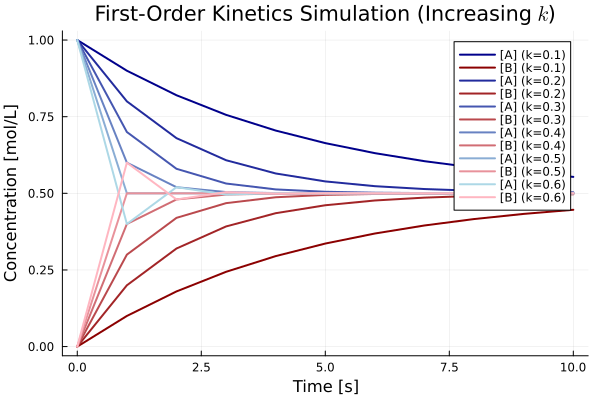

In [248]:
function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    k_1 = 0.1         # s^-1
    k_2 = 0.1         # s^-1
    delta_t = 1.0     # s
    T = 10            # s
    delta_k = 0.1     # s^-1
    num_steps = 6

    A_colors = palette(:blues, rev = true, num_steps)
    B_colors = palette(:reds, rev = true, num_steps)

    initial_plot = Plots.plot(
            title=raw"First-Order Kinetics Simulation (Increasing $k$)",
            xlabel="Time [s]",
            ylabel="Concentration [mol/L]",
    )

    open("S.Arnold_PS2_Q5di_output.txt", "w") do io
            write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, k_1=$k_1 s^-1, k_2=$k_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
            write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\n")

        
        for step in 0:(num_steps-1)
            t_array = []
            A_array = []
            B_array = []


            # initial values
            A = A_0
            B = B_0
            t = 0.0
            k_1_it = k_1 + step * delta_k
            k_2_it = k_2 + step * delta_k

            while t <= T
                push!(t_array, t)
                push!(A_array, A)
                push!(B_array, B)

                
                write(io, "$t\t$A\t$B\n")
                
                # Rate laws
                dA = (-k_1_it * A + k_2_it * B) * delta_t
                dB = (k_1_it * A - k_2_it * B) * delta_t
                
                A += dA
                B += dB
                t += delta_t
            end

            lbl_k = round(k_1_it, digits=2) 

            current_A_color = A_colors[step + 1]
            current_B_color = B_colors[step + 1]

            plot!(
                initial_plot,
                t_array,
                A_array,
                label="[A] (k=$lbl_k)", 
                color=current_A_color, 
                linewidth=2, 
            )

            plot!(
                initial_plot,
                t_array, 
                B_array, 
                label="[B] (k=$lbl_k)", 
                color=current_B_color, 
                linewidth=2, 
            )
        end
    end

    df = CSV.read("S.Arnold_PS2_Q5di_output.txt", DataFrame, delim='\t', comment="#")
    print(df)

    return initial_plot

end   

kinetics_simulation()


To make the simulation meaningful again, you need to decrease the step size, keeping the actual rates the same.

156×3 DataFrame
 Row │ Time(s)  [A](mol/L)  [B](mol/L) 
     │ Float64  Float64     Float64    
─────┼─────────────────────────────────
   1 │     0.0    1.0         0.0
   2 │     1.0    0.9         0.1
   3 │     2.0    0.82        0.18
   4 │     3.0    0.756       0.244
   5 │     4.0    0.7048      0.2952
   6 │     5.0    0.66384     0.33616
   7 │     6.0    0.631072    0.368928
   8 │     7.0    0.604858    0.395142
   9 │     8.0    0.583886    0.416114
  10 │     9.0    0.567109    0.432891
  11 │    10.0    0.553687    0.446313
  12 │    11.0    0.54295     0.45705
  13 │    12.0    0.53436     0.46564
  14 │    13.0    0.527488    0.472512
  15 │    14.0    0.52199     0.47801
  16 │    15.0    0.517592    0.482408
  17 │    16.0    0.514074    0.485926
  18 │    17.0    0.511259    0.488741
  19 │    18.0    0.509007    0.490993
  20 │    19.0    0.507206    0.492794
  21 │    20.0    0.505765    0.494235
  22 │    21.0    0.504612    0.495388
  23 │    22.0    0.503689   

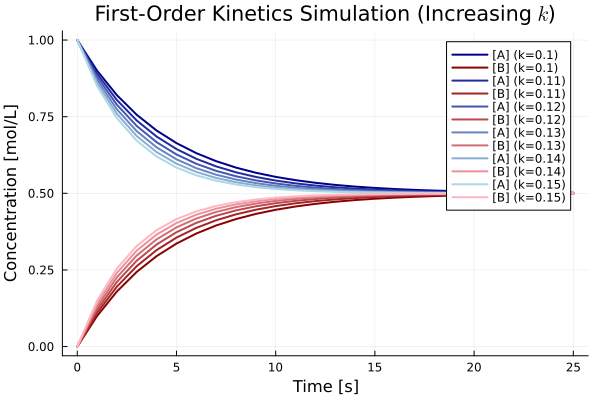

In [244]:
function kinetics_simulation()
    A_0 = 1.0         # mol/L
    B_0 = 0.0         # mol/L
    k_1 = 0.1         # s^-1
    k_2 = 0.1         # s^-1
    delta_t = 1.0     # s
    T = 25            # s
    delta_k = 0.01     # s^-1
    num_steps = 6

    A_colors = palette(:blues, rev = true, num_steps)
    B_colors = palette(:reds, rev = true, num_steps)

    initial_plot = Plots.plot(
            title=raw"First-Order Kinetics Simulation (Increasing $k$)",
            xlabel="Time [s]",
            ylabel="Concentration [mol/L]",
    )

    open("S.Arnold_PS2_Q5dii_output.txt", "w") do io
            write(io, "# Parameters: A_0=$A_0 mol/L, B_0=$B_0 mol/L, k_1=$k_1 s^-1, k_2=$k_2 s^-1, delta_t=$delta_t s, Simulation Time=$T s\n")
            write(io, "Time(s)\t[A](mol/L)\t[B](mol/L)\n")

        
        for step in 0:(num_steps-1)
            t_array = []
            A_array = []
            B_array = []


            # initial values
            A = A_0
            B = B_0
            t = 0.0
            k_1_it = k_1 + step * delta_k
            k_2_it = k_2 + step * delta_k

            while t <= T
                push!(t_array, t)
                push!(A_array, A)
                push!(B_array, B)

                
                write(io, "$t\t$A\t$B\n")
                
                # Rate laws
                dA = (-k_1_it * A + k_2_it * B) * delta_t
                dB = (k_1_it * A - k_2_it * B) * delta_t
                
                A += dA
                B += dB
                t += delta_t
            end

            lbl_k = round(k_1_it, digits=2) 

            current_A_color = A_colors[step + 1]
            current_B_color = B_colors[step + 1]

            plot!(
                initial_plot,
                t_array,
                A_array,
                label="[A] (k=$lbl_k)", 
                color=current_A_color, 
                linewidth=2, 
            )

            plot!(
                initial_plot,
                t_array, 
                B_array, 
                label="[B] (k=$lbl_k)", 
                color=current_B_color, 
                linewidth=2, 
            )
        end
    end

    df = CSV.read("S.Arnold_PS2_Q5dii_output.txt", DataFrame, delim='\t', comment="#")
    print(df)

    return initial_plot

end   

kinetics_simulation()
